# QFF 2026 Phase 1 - PS-01 / O1: Max-Cut on Weighted Graphs
**QAOA circuit construction & SWAP bottleneck analysis - Processor A vs Processor B**

![pipeline](assets/qff_phase1_latex_images/pipeline_overview.png)

One solution (QAOA, p = 1 and 2), run with identical parameters, shots, seeds and noise on the two official processors, plus an all-to-all reference that isolates the cost of routing. Run all cells top to bottom (about 2-4 minutes).

## 0. Configuration (identical for A and B)

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd
from IPython.display import display, Image
from src.problem import *
from src.processors import *
from src.experiment import *
from src.visualization import *

SELECTED_PS_CODE = "O1 / PS-01"
SELECTED_PS_NAME = "Max-Cut on Weighted Graphs (QAOA circuit construction & SWAP bottleneck analysis)"
P_VALUES, SHOTS, N_TRANSPILE_SEEDS, OPT_LEVEL = [1, 2], 4096, 10, 1
SEED_PARAMS, SEED_SIM, RESTARTS = 7, 2026, 20
FIG, TAB = Path("results/figures"), Path("results/tables")
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
print(SELECTED_PS_CODE, "-", SELECTED_PS_NAME)

O1 / PS-01 - Max-Cut on Weighted Graphs (QAOA circuit construction & SWAP bottleneck analysis)


## 1. Processors (official maps from the Processor A/B Benchmark Configuration)

In [2]:
procs = {"Processor A": load_processor("processors/processor_A.json"),
         "Processor B": load_processor("processors/processor_B.json")}
assert procs["Processor A"]["noise"] == procs["Processor B"]["noise"], "A and B must share the noise model"
assert procs["Processor A"]["basis_gates"] == procs["Processor B"]["basis_gates"]
for k, v in procs.items():
    print(k, "| qubits:", v["num_qubits"], "| edges:", v["coupling_map"])
    plot_topology(v, FIG / f"{k.lower().replace(' ', '_')}_graph.png")
print("noise:", {k: v for k, v in procs["Processor A"]["noise"].items() if k not in ("status", "source")})
print("NOTE:", procs["Processor A"]["noise"]["status"])

Processor A | qubits: 5 | edges: [[0, 1], [1, 2], [1, 3], [3, 4]]
Processor B | qubits: 9 | edges: [[0, 1], [1, 2], [1, 6], [2, 3], [2, 6], [2, 5], [3, 4], [4, 5], [5, 6], [6, 7], [6, 8], [8, 0]]
noise: {'one_qubit_depolarizing': 0.001, 'two_qubit_depolarizing': 0.005, 'readout_p01': 0.01, 'readout_p10': 0.02, 'noisy_gates_1q': ['x', 'sx'], 'noisy_gates_2q': ['cx']}
NOTE: ASSUMED - the organizer PDFs say 2Q ~0.5%, 1Q ~0.1% but do not freeze readout error. Replace with the official Challenge Kit values if/when published.


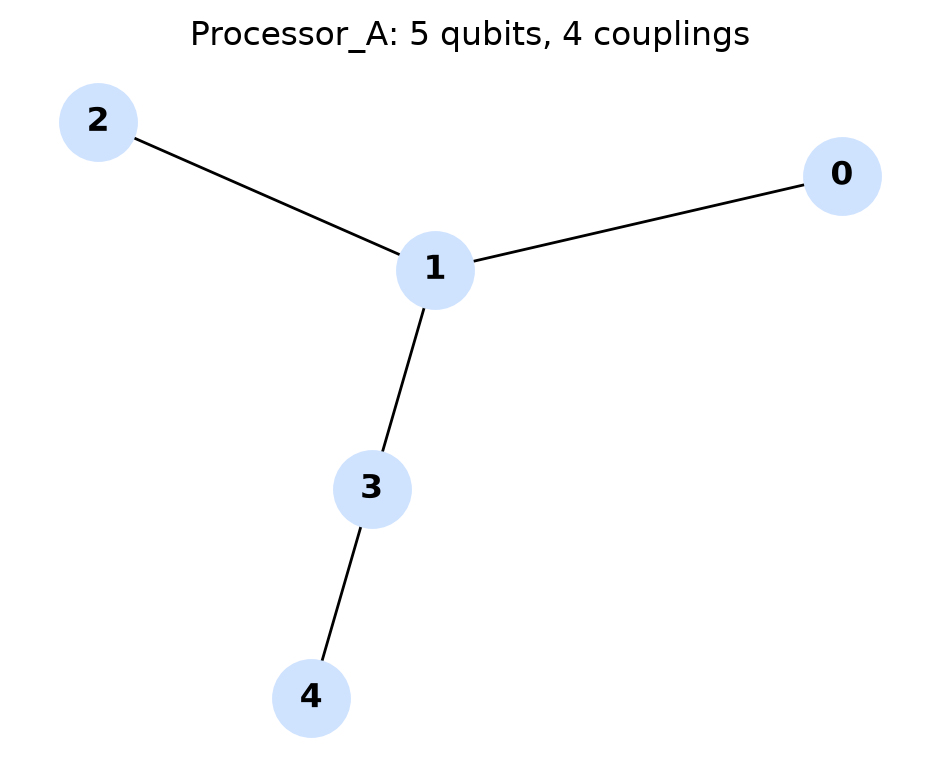

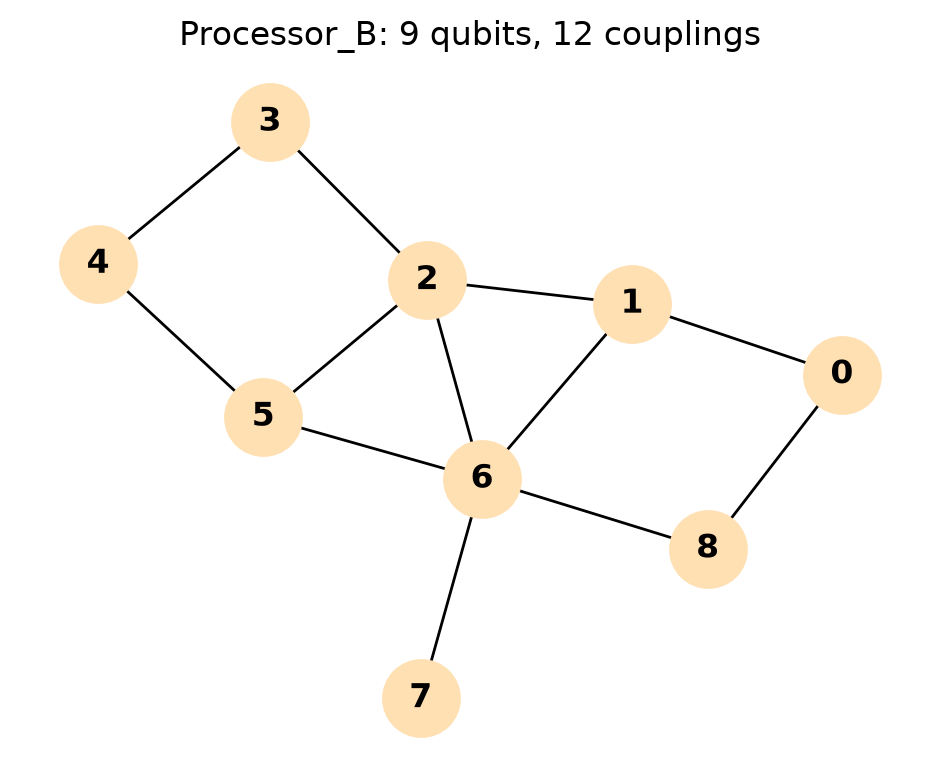

In [3]:
display(Image(FIG / "processor_a_graph.png", width=330)); display(Image(FIG / "processor_b_graph.png", width=330))

## 2. Problem instances and the exact classical optimum
Processor A has only 5 qubits, so the *common* benchmark uses 5-node graphs (G1-G3). G4 has 6 vertices (as in the PS text) and can only run on Processor B.

,graph,name,nodes,edges,total_weight,optimal_cut,n_optimal_bitstrings,runs_on
0,G1,dense_5node,5,8,19.0,15.0,2,A and B
1,G2,ring_chord_5node,5,6,24.0,22.0,2,A and B
2,G3,A_native_tree_5node,5,4,14.0,14.0,2,A and B
3,G4,custom_6node,6,9,28.0,28.0,2,B only


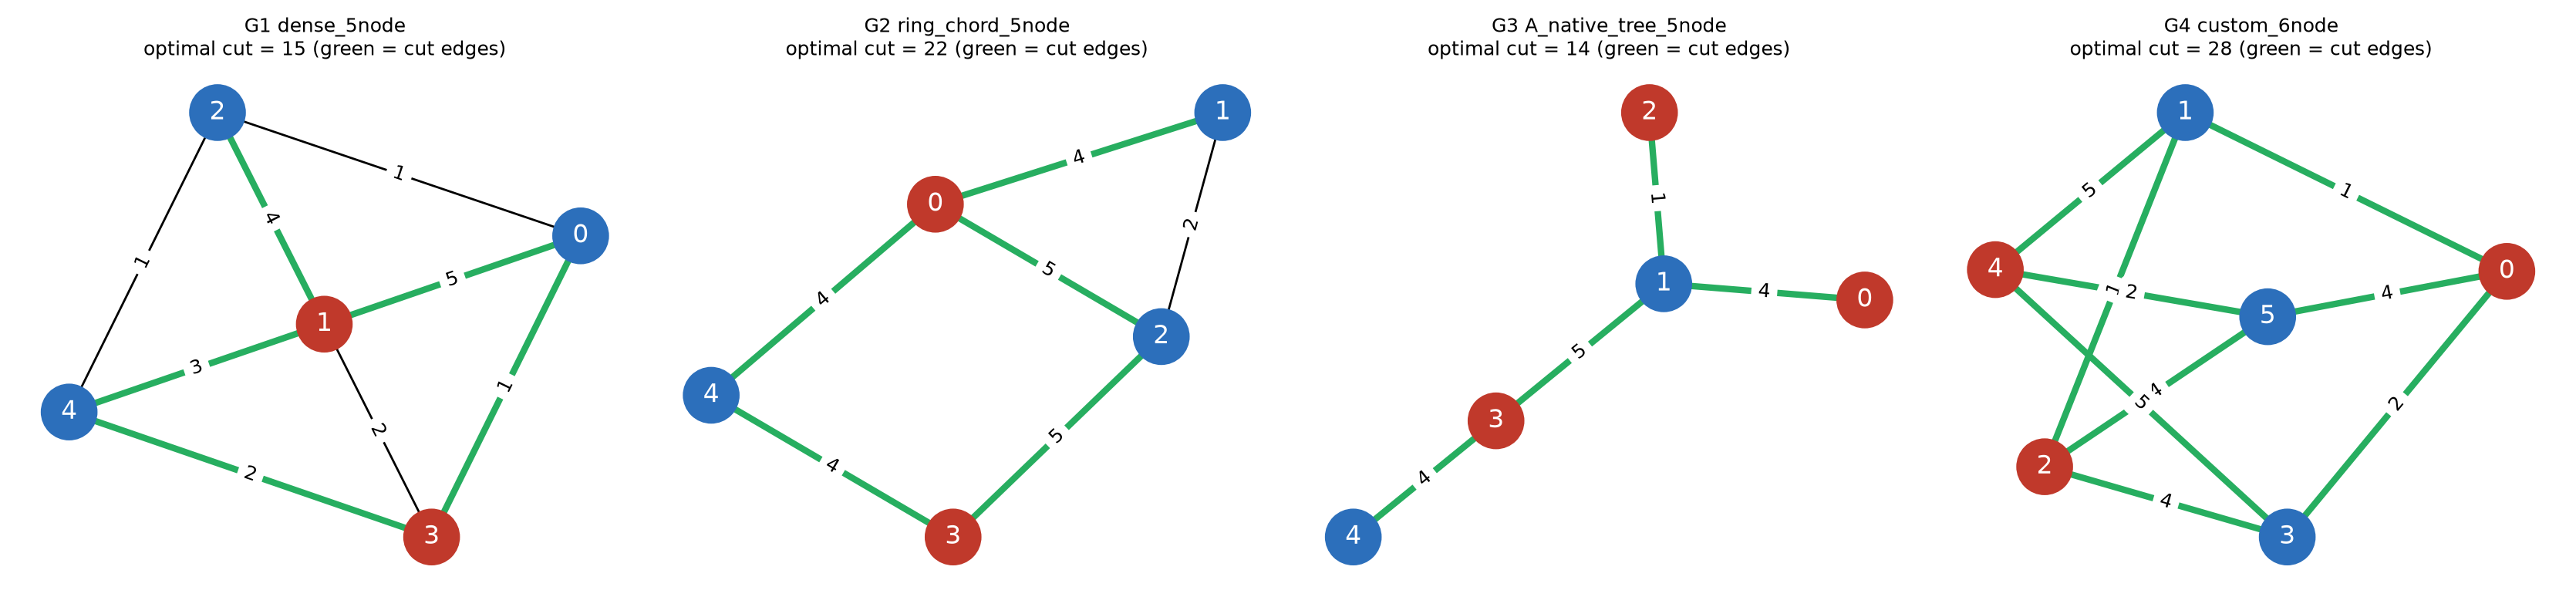

In [4]:
graphs = load_graphs("data/raw/graphs.json")
optima = {g["id"]: brute_force(g["num_nodes"], g["edges"]) for g in graphs}
rows = [dict(graph=g["id"], name=g["name"], nodes=g["num_nodes"], edges=len(g["edges"]),
             total_weight=sum(w for *_, w in g["edges"]), optimal_cut=optima[g["id"]][0],
             n_optimal_bitstrings=len(optima[g["id"]][1]), runs_on=("A and B" if g["num_nodes"] <= 5 else "B only"))
        for g in graphs]
baseline = pd.DataFrame(rows); baseline.to_csv(TAB / "classical_baseline.csv", index=False); display(baseline)
plot_problem_graphs(graphs, optima, FIG / "problem_graphs.png"); display(Image(FIG / "problem_graphs.png"))

## 3. QAOA: ideal landscape and parameter optimisation
$\gamma,\beta$ are optimised **once** on the noiseless simulator (seeded multi-start COBYLA) and reused unchanged on A and B.

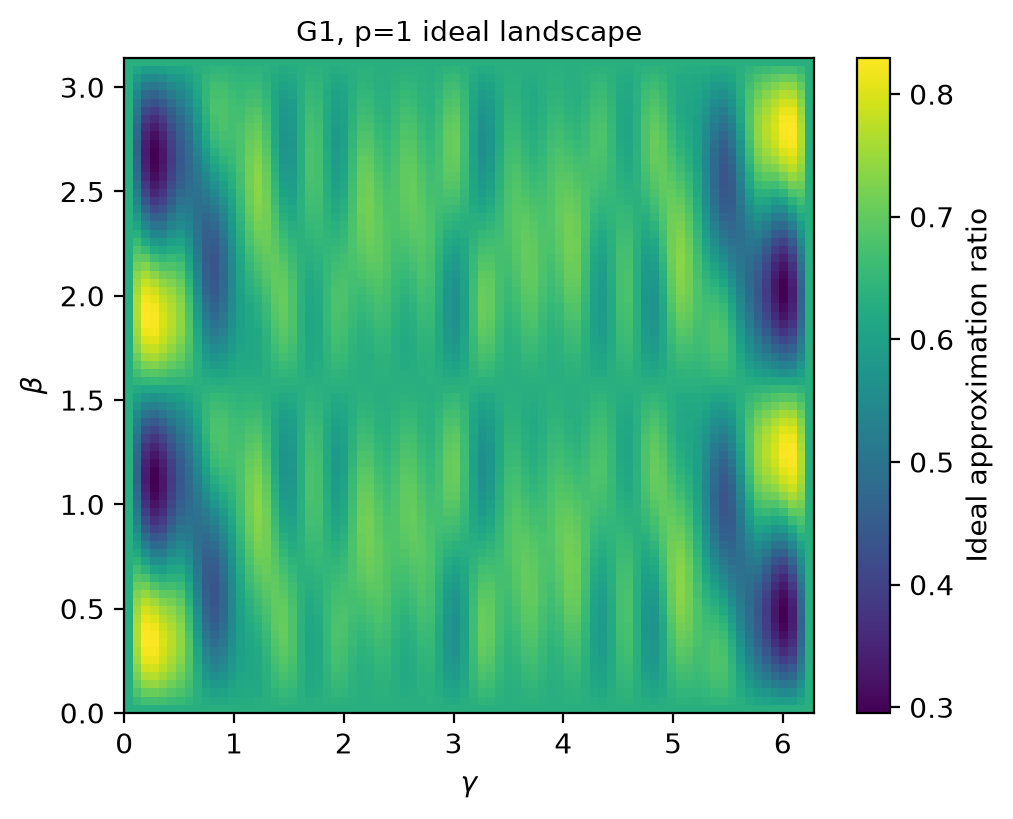

In [5]:
g1 = graphs[0]; n1, e1 = g1["num_nodes"], g1["edges"]; tab1, diag1 = cut_table(n1, e1), zz_diag(n1, e1)
gg, bb = np.linspace(0, 2 * np.pi, 80), np.linspace(0, np.pi, 80)
F = np.array([[np.abs(qaoa_state(n1, diag1, [g], [b])) ** 2 @ tab1 for g in gg] for b in bb])
plot_landscape(gg, bb, F, optima["G1"][0], FIG / "qaoa_landscape_G1_p1.png", "G1, p=1 ideal landscape")
display(Image(FIG / "qaoa_landscape_G1_p1.png", width=420))

In [ ]:
inst = prepare_instances(graphs, P_VALUES, seed=SEED_PARAMS, restarts=RESTARTS)
par = pd.DataFrame([dict(graph=k[0], p=k[1], gammas=list(np.round(d["gammas"], 4)), betas=list(np.round(d["betas"], 4)),
                         ideal_expected_cut=d["ideal_exp"], optimum=d["opt"], ideal_ratio=d["ideal_exp"] / d["opt"],
                         random_ratio=d["random_exp"] / d["opt"]) for k, d in inst.items()])
par.to_csv(TAB / "qaoa_parameters.csv", index=False); display(par.round(4))

In [ ]:
# processed data for the repo: exact optima + optimised parameters
processed = {"optima": {gid: {"optimal_cut": v[0], "optimal_bitstrings_msb_first": v[1]} for gid, v in optima.items()},
             "qaoa_parameters": {f"{k[0]}_p{k[1]}": {"gammas": [float(x) for x in d["gammas"]], "betas": [float(x) for x in d["betas"]],
                                                    "ideal_expected_cut": float(d["ideal_exp"])} for k, d in inst.items()}}
Path("data/processed").mkdir(parents=True, exist_ok=True)
Path("data/processed/optima_and_qaoa_parameters.json").write_text(json.dumps(processed, indent=2))
print("saved data/processed/optima_and_qaoa_parameters.json")

## 4. A/B benchmark: transpile -> execute (noisy) -> measure
For each (graph, p, processor) the circuit is transpiled with **10 transpiler seeds** (the layout/routing heuristic is stochastic) and every compiled circuit is executed with the same noise model. We report mean +/- std over seeds.

In [ ]:
runs, circuits = run_benchmark(inst, procs, shots=SHOTS, n_seeds=N_TRANSPILE_SEEDS, opt_level=OPT_LEVEL, sim_seed=SEED_SIM)
runs.to_csv(TAB / "all_runs.csv", index=False)
summ = summarise(runs); summ.to_csv(TAB / "summary_by_graph.csv", index=False)
print(len(runs), "compiled+executed circuits")

## 5. A vs B comparison tables

In [ ]:
cols = ["graph", "p", "processor", "swaps_mean", "swaps_std", "twoq_mean", "twoq_std", "depth_mean", "depth_std",
        "ratio_mean", "ratio_std", "p_opt_mean", "fidelity_mean", "qubits_used", "ideal_ratio", "random_ratio"]
display(summ[cols].round(3))

In [ ]:
# guide section 15 format: Metric | A | B | difference, for the common graphs (mean over graphs and seeds)
common = [g["id"] for g in graphs if g["num_nodes"] <= 5]
rows = []
for p in P_VALUES:
    d = runs[(runs.graph.isin(common)) & (runs.p == p)]
    a, b = d[d.processor == "Processor A"], d[d.processor == "Processor B"]
    ref = d[d.processor == ALL2ALL]
    for name, col in [("Approx. ratio (expected cut / optimum)", "approx_ratio_expected"), ("P(optimal cut)", "p_optimal"),
                      ("Distribution fidelity vs ideal", "dist_fidelity"), ("Depth", "depth"), ("2Q gates (CX)", "two_qubit_gates"),
                      ("SWAPs", "swaps"), ("Extra 2Q gates vs logical", "extra_2q_vs_logical"),
                      ("Physical qubits used", "physical_qubits_used"), ("Transpile time (s)", "transpile_time_s")]:
        rows.append({"p": p, "Metric": name, "Processor A": a[col].mean(), "Processor B": b[col].mean(),
                     "B - A": b[col].mean() - a[col].mean(), "All-to-all ref": ref[col].mean()})
final = pd.DataFrame(rows); final.to_csv(TAB / "final_comparison.csv", index=False)
for p in P_VALUES: display(final[final.p == p].drop(columns="p").round(4).reset_index(drop=True))

In [ ]:
per_proc = {k: runs[runs.processor == k] for k in ["Processor A", "Processor B"]}
for k, v in per_proc.items(): v.to_csv(TAB / f"{k.lower().replace(' ', '_')}_metrics.csv", index=False)
summ.to_csv(TAB / "AB_comparison.csv", index=False)
print("saved tables:", sorted(x.name for x in TAB.glob("*.csv")))

In [ ]:
# is the A-vs-B quality difference larger than shot noise? (conservative: single-run shot SE for each side)
rows = []
for gid in common:
    for p in P_VALUES:
        a = runs[(runs.graph == gid) & (runs.p == p) & (runs.processor == "Processor A")]
        b = runs[(runs.graph == gid) & (runs.p == p) & (runs.processor == "Processor B")]
        opt_ = inst[(gid, p)]["opt"]
        d = (b.expected_cut.mean() - a.expected_cut.mean()) / opt_
        se = np.hypot(a.expected_cut_se.mean(), b.expected_cut_se.mean()) / opt_
        rows.append(dict(graph=gid, p=p, ratio_A=a.approx_ratio_expected.mean(), ratio_B=b.approx_ratio_expected.mean(),
                         delta_B_minus_A=d, shot_se=se, z=d / se, swaps_A=a.swaps.mean(), swaps_B=b.swaps.mean()))
sig = pd.DataFrame(rows); sig.to_csv(TAB / "quality_significance.csv", index=False); display(sig.round(4))

## 6. Figures

In [ ]:
plot_ab_summary(summ, FIG / "AB_performance.png"); plot_tradeoff(summ, FIG / "architecture_tradeoffs.png")
display(Image(FIG / "AB_performance.png")); display(Image(FIG / "architecture_tradeoffs.png", width=560))

In [ ]:
# logical vs transpiled circuits (best seed) for G1, p = 1
logical = build_qaoa(n1, e1, inst[("G1", 1)]["gammas"], inst[("G1", 1)]["betas"])
save_circuit(logical, FIG / "logical_circuit_G1_p1.png")
for lab in ["Processor A", "Processor B"]:
    save_circuit(circuits[("G1", 1, lab)]["circuit"], FIG / f"transpiled_{lab[-1]}_G1_p1.png")
display(Image(FIG / "logical_circuit_G1_p1.png")); display(Image(FIG / "transpiled_A_G1_p1.png")); display(Image(FIG / "transpiled_B_G1_p1.png"))

In [ ]:
# measured output distributions (G1, p=1): ideal vs noisy A vs noisy B
d = inst[("G1", 1)]
plot_distributions({k: circuits[("G1", 1, k)]["probs"] for k in ["Processor A", "Processor B"]}, d["ideal_probs"], d["n"],
                   d["opt_bits"], FIG / "distributions_G1_p1.png", title="G1, p=1")
display(Image(FIG / "distributions_G1_p1.png"))

## 7. Correctness checks
(1) Transpiling must not change the computation: the noiseless compiled circuit must reproduce the ideal expected cut. (2) Every CX must sit on a physical coupling edge.

In [ ]:
chk = runs.dropna(subset=["noiseless_compiled_expected_cut"]).copy()
chk["abs_diff"] = (chk.noiseless_compiled_expected_cut - chk.ideal_expected_cut).abs()
display(chk[["graph", "p", "processor", "ideal_expected_cut", "noiseless_compiled_expected_cut", "abs_diff"]].round(4))
assert chk.abs_diff.max() < 0.03, "compiled circuit deviates from ideal beyond shot noise"
for (gid, p, lab), v in circuits.items():
    if lab in procs:
        cm = set(coupling_map(procs[lab]).get_edges())
        for inst_ in v["circuit"].data:
            if inst_.operation.name == "cx":
                assert tuple(v["circuit"].find_bit(q).index for q in inst_.qubits) in cm
print("checks passed; max deviation:", round(chk.abs_diff.max(), 4))

## 8. Findings (written analysis; full version in `report.md`)
**Setup.** Same QAOA parameters, 4096 shots, seeds and noise (2Q 0.5%, 1Q 0.1%, assumed readout) on Processor A (5 qubits, tree) and Processor B (9 qubits, 12 couplings), 10 transpiler seeds each, plus an all-to-all reference.

**What changed / which property.** Connectivity. At p=2 (G1-G3 mean) A needs 5.0 SWAPs / 39.0 CX / depth 66 versus 1.1 SWAPs / 27.1 CX / depth 52 on B (all-to-all: 24 CX, depth 45). Gate set, noise and qubits used (5) are identical, so the difference is attributable to topology. Extra CX = 3 x SWAPs (A, p=2: 15.1 predicted, 15.0 measured).

**Evidence.** G2 (triangle + 4-cycle) is a subgraph of B -> 0 SWAPs on B, 7 on A. G3's interaction graph equals A's coupling map -> 0 SWAPs on both and no quality difference (z = -0.4, -0.6): a control. Quality difference B - A is +0.023 for G2 p=2 (z = 4.7), +0.009 for G1 p=2 (z = 2.1), and not significant at p=1.

**Phase 2 readiness.** Bottleneck: A's tree topology costs ~3 CX per SWAP for every cyclic graph, compounding with p. Layout/interaction-graph matching removes the overhead entirely (G3). Routing cost is stochastic (up to +/-1.5 CX across transpiler seeds), so report distributions.

**Limitations.** Assumed noise parameters; team-generated graphs (official ones not supplied); G4 (6 nodes) runs on B only because A has 5 qubits; noiseless (not noise-aware) parameter optimisation; Aer simulation, so runtime is simulator wall-clock; noise costs more quality than routing, and p=2 still beats p=1 on G1-G3.